# 3.7 - A revised long-only strategy, specified before it ran

> **Needs:** the research cache with analysts' estimates (source `estimates`, and `estimates_uk` for London) and the
> database, where every run is registered.
>
> **Produces:** two registered runs of the new family `revised_lo` - the specification on the S&P 1500, then unchanged
> on the FTSE All-Share.

A review of notebooks 3.1-3.6 (`docs/STRATEGY_REVIEW.md`, 20 November 2026) found that their scores carry some
information but their portfolios lose most of it, and that several measurements were wrong. The measurements were
fixed first:

* **Analysts' revision counts were a snapshot, not a history.** LSEG answers `TR.NumEstRevisingUp` / `Down` with the
  counts of the day it is asked, whatever date the request names: 99.6 % of the counts stored for 2000-2026 equal
  each company's latest (GE: 21 raised, 0 lowered in every June from 2000 to 2026). Every backtest that used them
  ranked 2004's stocks on 2026's revisions. Research now reads only counts asked within a month of their date, so
  no backtest before the refresh starts collecting them has any; the consensus revisions - a true history - stand in.
* **A yield over a negative enterprise value** ranked a profitable company holding more cash than its value and debt
  as the dearest stock; EBIT / EV is now missing there, as free cash flow / EV already was.
* **A book that holds nothing is refused**, naming when it first can hold names (3.3's learned score held cash for
  its first three years without saying so).

Then the review's recommendations were turned into settings of the factor strategy, each a choice of its own:

| Setting | Notebooks 3.1-3.6 | Here |
|---|---|---|
| Signals | value (four yields), quality, momentum, low volatility, net issuance | **quality, net issuance, earnings value** (EBIT / EV, earnings / price, free cash flow / EV) and the **consensus revision** of EPS over four months - the inputs with the strongest evidence in 3.2, 3.6 and 5.2; book and sales yields, momentum and low volatility dropped |
| Mixing | a factor's average of z-scores spread less than one z-score, and a missing factor was skipped | each factor **z-scored again** before the equal-weighted mix; a missing factor **counts as neutral** |
| Ranking | across the whole universe (3.1's first book: 37 % financials) | **within GICS sectors** |
| Construction | the best 10-30 % by score, equally or cap-weighted | **the universe by market value plus tilts** on notebook 4.2's risk model: **2 %** predicted active risk a year, at most **1 %** active in any name, **no sector, size or beta bet**, never short |
| Trading | every holding reset to its target each month | a holding within **25 %** of its target is not traded |
| Benchmark | SPTM, a fund that tracked other indices until 2020 | **the universe's own members by market value**, rebuilt from our data |

**The specification, fixed before the first run** (family `revised_lo`, one run per universe):

* the S&P 1500 from January 2004 to December 2024 (the hold-out from 2025 stays shut), each segment's trading costs
  (0.10 / 0.25 / 0.50 % a trade), monthly;
* then the same settings, unchanged, on the **FTSE All-Share** - a universe no strategy of this repository has been
  tested on, the nearest thing to out-of-sample these years offer (London's costs, and stamp duty on purchases).

**The pass mark, written before the run.** The specification passes if all three hold:

1. on the S&P 1500, its active return against its own index after costs is above zero, with a t-statistic of the
   mean monthly difference of at least 1.0;
2. on the FTSE All-Share, unchanged, its active return after costs is above zero;
3. on the S&P 1500 at **twice** the assumed trading costs, its active return is still above zero.

**Measured twice, run once.** The first execution (runs 195 and 196, 20 November 2026) compared each book with an
index that had a return only on the last trading day of each month: the universe's market values are dated on
rebalance dates, and the benchmark read them as if they were daily (a bug, since fixed: the index now holds the
month-end weights between rebalances, `construction.index_returns`, and `cap_weighted` refuses month-end values).
Its pass-mark verdict was meaningless. The specification was not changed: the same two configurations were measured
again - the registry counts them as the same two trials, and the books are identical. Its measures against SPTM and
SPY, from daily fund prices, were right the first time and are unchanged.

A t of 1 is a low bar on purpose: an information ratio of 0.3 - good for a long-only book - reaches a t of 2 only
after 44 years, so one backtest cannot prove a modest edge; agreement across two markets and a margin over costs say
more. **The signals were chosen from the same 2004-2024 years** (3.2, 3.6, 5.2 saw them), so the S&P 1500 result is
not out of sample: its deflated Sharpe ratio is shown counting every long-only trial of notebooks 3.1-3.6 as well.

In [1]:
from dataclasses import replace

import pandas as pd
from IPython.display import Markdown, display

from equity_research.analytics.indices import vendor_returns
from equity_research.data.cache import ResearchCache
from equity_research.data.sectors import listing_sectors
from equity_research.strategies import construction as cn
from equity_research.strategies.factor_strategy import StrategyConfig, run_strategy
from research_core import charts
from research_core.analytics.performance.metrics import active_performance, monthly_pair, performance
from research_core.analytics.performance.tracking import calendar_years
from research_core.data.db.engine import get_engine
from research_core.engine.finish import deflated_active
from research_core.engine.registry import trial_count

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# The specification - every setting fixed before the first run (see the introduction). Changing any of them is a new
# trial of the family, registered and counted.
SIGNALS = {"quality": 1.0, "issuance": 1.0, "earnings_value": 1.0, "consensus_revisions": 1.0}
SPEC = StrategyConfig(
    family="revised_lo",
    universe="SP1500",
    start="2004-01-01",
    end="2024-12-31",
    factors=tuple(SIGNALS.items()),
    long_only=True,
    beta_neutral=False,
    mix="standardised",
    within_sectors=True,
    construction="tilted",
    risk=0.02,
    max_active=0.01,
    neutral=("sector", "size"),
    benchmark="cap_weighted",
    drift_band=0.25,
)
REPLICATION = replace(SPEC, universe="FTSEAS")  # the one change: the universe
PASS_T = 1.0  # pass mark 1: the t-statistic of the mean monthly active return on the S&P 1500
# Every long-only family of notebooks 3.1-3.6: the specification is one more try at their question
EARLIER = ("multi_factor_lo", "value_only_lo", "garp_sp500", "qgarp")

results = {"S&P 1500": run_strategy(cache, SPEC, engine=engine)}
results["FTSE All-Share"] = run_strategy(cache, REPLICATION, engine=engine)
for name, r in results.items():
    print(f"{name}: registered as run {r.run_id}; trials of revised_lo so far: {r.metrics['trials']}")

left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


left out 934 facts of 2 companies in ['USD']


left out 1281 facts of 3 companies in ['USD']


left out 934 facts of 2 companies in ['USD']


left out 1274 facts of 2 companies in ['USD']


S&P 1500: registered as run 244; trials of revised_lo so far: 2
FTSE All-Share: registered as run 245; trials of revised_lo so far: 2


## Against its own index

Each book against its universe's members weighted by market value (the benchmark the construction tilts away from),
after costs. `active_t` is the t-statistic of the mean monthly active return; the deflated active Sharpe ratio is
the probability that the active bet reflects skill, first for this family's trials alone, then counting every
long-only trial of notebooks 3.1-3.6 too.

In [2]:
rows = {}
for name, r in results.items():
    net = r.backtest.net
    pair = monthly_pair(net, r.benchmark)
    diff = pair["r"] - pair["b"]
    m = r.metrics
    trials_all = int(m["trials"]) + sum(trial_count(engine, f) for f in EARLIER)
    rows[name] = {
        "cagr": m["cagr"],
        "index cagr": performance(r.benchmark.reindex(net.index).dropna())["cagr"],
        "vol": m["vol"],
        "max_drawdown": m["max_drawdown"],
        "beta": m["beta"],
        "alpha": m["alpha"],
        "active_return": m["active_return"],
        "tracking_error": m["tracking_error"],
        "information_ratio": m["information_ratio"],
        "active_t": float(diff.mean() / diff.std() * len(diff) ** 0.5),
        "turnover": m["turnover"],
        "deflated (this family)": m["deflated_active_sharpe"],
        "deflated (all long-only trials)": deflated_active(net, r.benchmark, m["information_ratio"], trials_all),
        "trials counted": trials_all,
    }
table = pd.DataFrame(rows).T
STYLE = {
    "cagr": "{:.1%}",
    "index cagr": "{:.1%}",
    "vol": "{:.1%}",
    "max_drawdown": "{:.0%}",
    "beta": "{:.2f}",
    "alpha": "{:+.2%}",
    "active_return": "{:+.2%}",
    "tracking_error": "{:.2%}",
    "information_ratio": "{:+.2f}",
    "active_t": "{:+.2f}",
    "turnover": "{:.1f}",
    "deflated (this family)": "{:.0%}",
    "deflated (all long-only trials)": "{:.0%}",
    "trials counted": "{:.0f}",
}
display(table.style.format(STYLE))

# cross-checks for the S&P 1500: the investable fund, the equal-weighted universe and the S&P 500 fund
sp = results["S&P 1500"]
checks = {
    "own index (by market value)": sp.benchmark,
    "SPTM (fund)": vendor_returns(cache, "SPTM", total=True),
    "SPY (fund)": vendor_returns(cache, "SPY", total=True),
}
shown = ["beta", "alpha", "active_return", "tracking_error", "information_ratio"]
display(
    pd.DataFrame({k: active_performance(sp.backtest.net, b) for k, b in checks.items()})
    .T[shown]
    .style.format({k: STYLE[k] for k in shown})
)

,cagr,index cagr,vol,max_drawdown,beta,alpha,active_return,tracking_error,information_ratio,active_t,turnover,deflated (this family),deflated (all long-only trials),trials counted
S&P 1500,10.7%,10.3%,18.8%,-54%,0.99,+0.56%,+0.41%,2.61%,+0.16,+0.73,3.6,58%,6%,46
FTSE All-Share,8.4%,7.3%,16.8%,-43%,1.00,+1.01%,+0.99%,2.06%,+0.49,+2.24,2.9,96%,50%,46


,beta,alpha,active_return,tracking_error,information_ratio
own index (by market value),0.99,+0.56%,+0.41%,2.61%,+0.16
SPTM (fund),0.98,+0.62%,+0.38%,3.01%,+0.12
SPY (fund),1.00,+0.43%,+0.42%,2.89%,+0.16


Each year: the book's return minus its own index's


,S&P 1500,FTSE All-Share
trade_date,,
2004,+3.5%,+0.9%
2005,+1.3%,+0.2%
2006,+1.3%,-2.4%
2007,-1.0%,-1.6%
2008,+2.5%,+3.3%
2009,+1.7%,+4.9%
2010,-1.0%,-2.1%
2011,+4.4%,+2.2%
2012,-4.5%,+1.9%


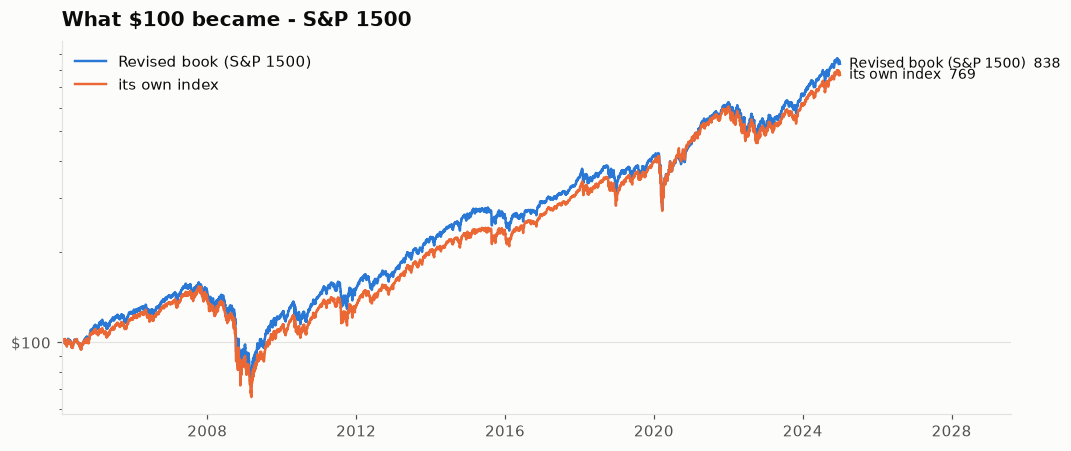

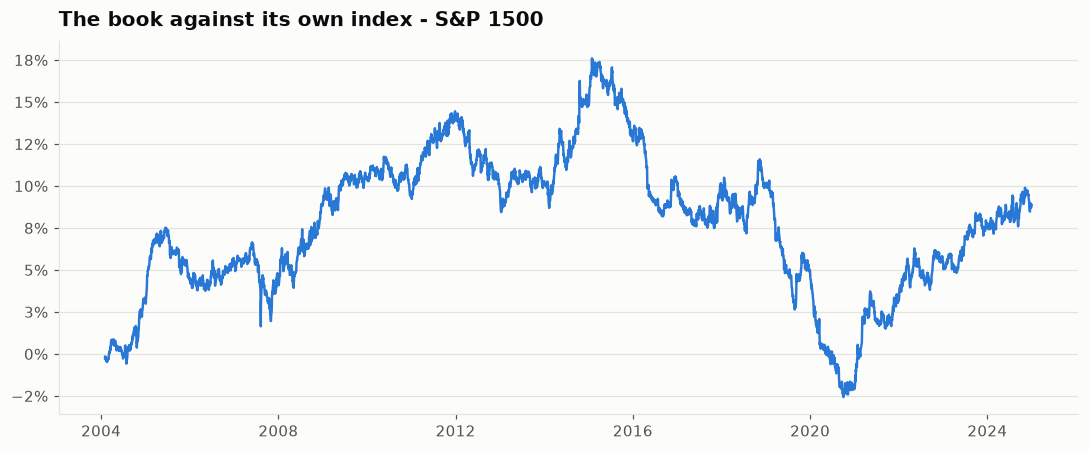

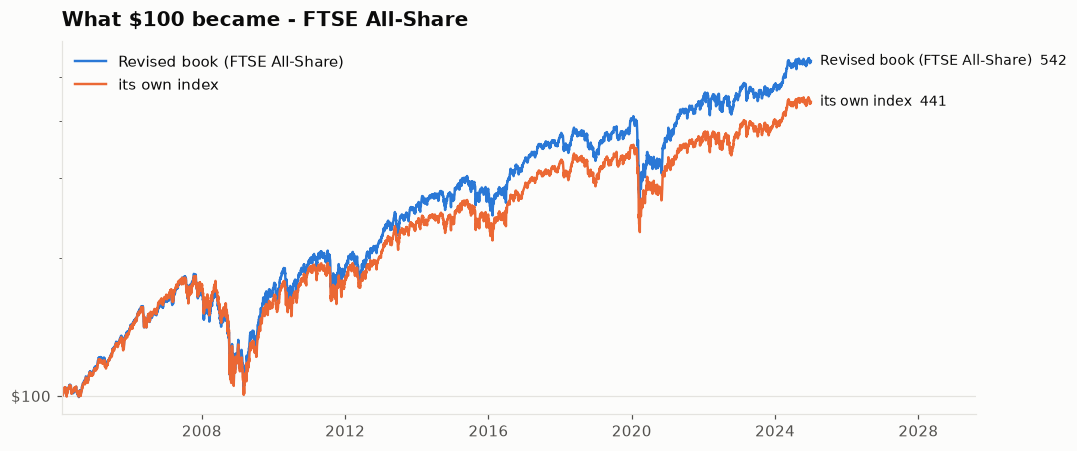

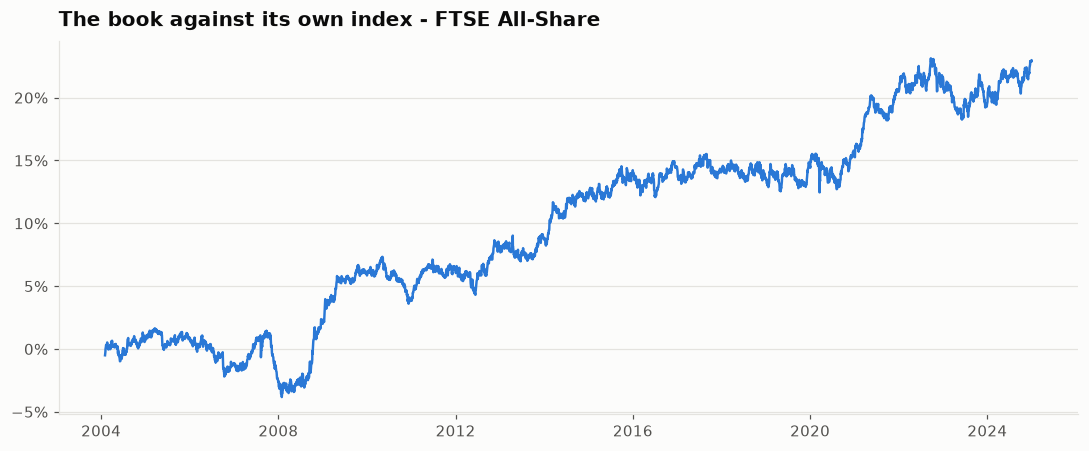

In [3]:
for name, r in results.items():
    fig = charts.growth(
        {f"Revised book ({name})": r.backtest.net, "its own index": r.benchmark}, f"What $100 became - {name}"
    )
    both = pd.concat({"book": r.backtest.net, "index": r.benchmark}, axis=1, sort=True).dropna()
    relative = (1 + both["book"]).cumprod() / (1 + both["index"]).cumprod() - 1
    fig = charts.lines(
        {"ahead of its own index by": relative}, f"The book against its own index - {name}", percent=True
    )
years = pd.DataFrame(
    {
        name: calendar_years({"book": r.backtest.net, "index": r.benchmark}).pipe(lambda y: y["book"] - y["index"])
        for name, r in results.items()
    }
)
print("Each year: the book's return minus its own index's")
display(years.style.format("{:+.1%}", na_rep=""))

## Costs, and the pass mark

The trading costs each book paid a year, and its active return if every trade had cost twice as much (the gross
returns less the costs twice over). Then the three conditions of the pass mark, checked here - not read off by eye.

In [4]:
stress = {}
for name, r in results.items():
    years_run = len(r.backtest.net) / 252
    twice = r.backtest.net - r.backtest.costs
    stress[name] = {
        "costs a year": float(r.backtest.costs.sum() / years_run),
        "active return": r.metrics["active_return"],
        "active return at twice the costs": active_performance(twice, r.benchmark)["active_return"],
    }
stress = pd.DataFrame(stress).T
display(stress.style.format("{:+.2%}"))
conditions = {
    f"1. S&P 1500: active return above 0, t at least {PASS_T:.1f}": bool(
        table.loc["S&P 1500", "active_return"] > 0 and table.loc["S&P 1500", "active_t"] >= PASS_T
    ),
    "2. FTSE All-Share, unchanged: active return above 0": bool(table.loc["FTSE All-Share", "active_return"] > 0),
    "3. S&P 1500 at twice the costs: active return above 0": bool(
        stress.loc["S&P 1500", "active return at twice the costs"] > 0
    ),
}
passed = all(conditions.values())
display(pd.Series(conditions, name="met").to_frame())
print("The specification", "PASSES" if passed else "does NOT pass", "its pass mark")

,costs a year,active return,active return at twice the costs
S&P 1500,+0.67%,+0.41%,-0.27%
FTSE All-Share,+1.48%,+0.99%,-0.49%


,met
"1. S&P 1500: active return above 0, t at least 1.0",False
"2. FTSE All-Share, unchanged: active return above 0",True
3. S&P 1500 at twice the costs: active return above 0,False


The specification does NOT pass its pass mark


## What the books hold

The construction's promises, checked on what it held: how many names, how far from the index (active share: half the
sum of the differences in weight), the realised beta to its own index, and on the last rebalance the sector weights
against the index's.

left out 1078 facts of 2 companies in ['GBP']


left out 934 facts of 2 companies in ['USD']


left out 1281 facts of 3 companies in ['USD']


,names held (average),members (average),active share (average),largest active weight,realised beta to its index
S&P 1500,199,1500,55%,1.00%,0.99
FTSE All-Share,83,509,40%,1.00%,1.00


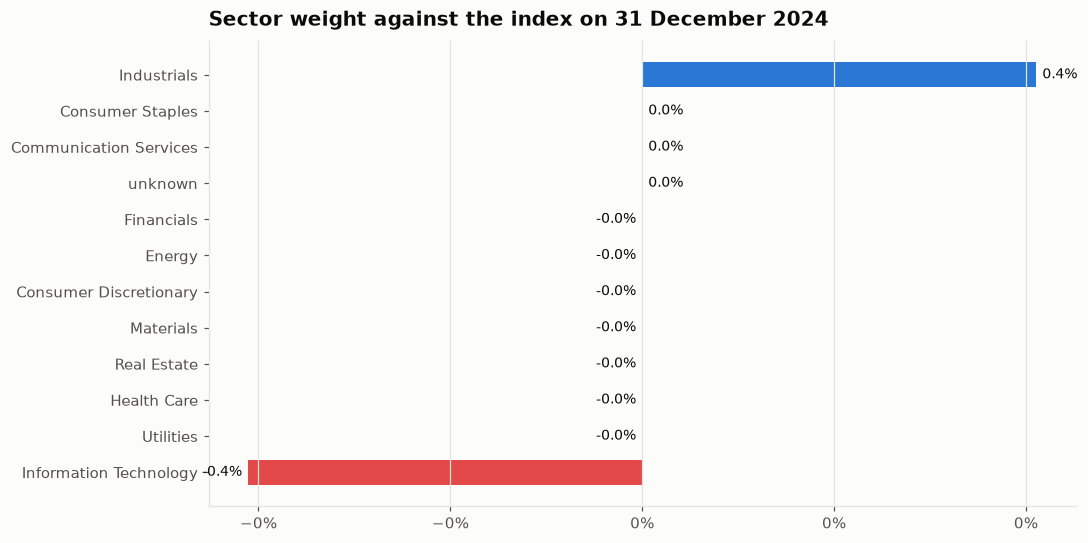

In [5]:
from equity_research.data.universe import load_universe_data

held = {}
for name, r in results.items():
    book = r.book
    data = load_universe_data(cache, r.config.universe, r.config.start, r.config.end)
    index = pd.DataFrame({d: cn.index_weights(data, d) for d in book.index}).T.reindex(columns=book.columns).fillna(0.0)
    active_share = (book - index).abs().sum(axis=1) / 2
    held[name] = {
        "names held (average)": float((book > 0).sum(axis=1).mean()),
        "members (average)": float((index > 0).sum(axis=1).mean()),
        "active share (average)": float(active_share.mean()),
        "largest active weight": float((book - index).abs().max().max()),
        "realised beta to its index": r.metrics["beta"],
    }
    if name == "S&P 1500":
        day = book.index[-1]
        sectors = listing_sectors(cache, book.columns, day)
        tilt = (book.loc[day] - index.loc[day]).groupby(sectors.reindex(book.columns).to_numpy()).sum()
        fig = charts.ranked_bars(tilt.sort_values(), f"Sector weight against the index on {day:%d %B %Y}", percent=True)
display(
    pd.DataFrame(held).T.style.format(
        {
            "names held (average)": "{:.0f}",
            "members (average)": "{:.0f}",
            "active share (average)": "{:.0%}",
            "largest active weight": "{:.2%}",
            "realised beta to its index": "{:.2f}",
        }
    )
)

## Findings

Printed from the results above, so they cannot fall out of step with them (the review found four notebooks whose
typed findings no longer matched their tables).

In [6]:
sp_row, uk_row = table.loc["S&P 1500"], table.loc["FTSE All-Share"]
costs, sp_held = stress["costs a year"], held["S&P 1500"]
lines = [
    f"**The specification {'passes' if passed else 'does not pass'} the pass mark written before the run** "
    f"({sum(conditions.values())} of 3 conditions met).",
    "",
    f"* **S&P 1500, 2004-2024:** {sp_row['cagr']:.1%} a year against its own index's {sp_row['index cagr']:.1%}: "
    f"an active return of {sp_row['active_return']:+.2%} a year after costs, tracking error "
    f"{sp_row['tracking_error']:.2%}, information ratio {sp_row['information_ratio']:+.2f} "
    f"(t {sp_row['active_t']:+.2f}), beta {sp_row['beta']:.2f}, alpha {sp_row['alpha']:+.2%}, turnover "
    f"{sp_row['turnover']:.1f} a year.",
    f"* **FTSE All-Share, unchanged:** {uk_row['cagr']:.1%} a year against its own index's "
    f"{uk_row['index cagr']:.1%}: active return {uk_row['active_return']:+.2%} a year, tracking error "
    f"{uk_row['tracking_error']:.2%}, information ratio {uk_row['information_ratio']:+.2f} "
    f"(t {uk_row['active_t']:+.2f}), beta {uk_row['beta']:.2f}.",
    f"* **Costs:** {costs['S&P 1500']:.2%} a year on the S&P 1500 and {costs['FTSE All-Share']:.2%} on the FTSE "
    "All-Share (stamp duty included); at twice the costs the S&P 1500 book's active return is "
    f"{stress.loc['S&P 1500', 'active return at twice the costs']:+.2%} a year.",
    f"* **Evidence after the search:** the deflated active Sharpe ratio is {sp_row['deflated (this family)']:.0%} "
    f"for this family's trials alone and {sp_row['deflated (all long-only trials)']:.0%} counting all "
    f"{int(sp_row['trials counted'])} long-only trials of notebooks 3.1-3.7.",
    f"* **The construction kept its promises:** {sp_held['names held (average)']:.0f} names held of "
    f"{sp_held['members (average)']:.0f} on average, active share {sp_held['active share (average)']:.0%}, "
    f"realised beta {sp_held['realised beta to its index']:.2f} to its index (the books of notebooks 3.1-3.6: 0.8 "
    "to 1.2 against their benchmarks).",
]
display(Markdown("\n".join(lines)))

**The specification does not pass the pass mark written before the run** (1 of 3 conditions met).

* **S&P 1500, 2004-2024:** 10.7% a year against its own index's 10.3%: an active return of +0.41% a year after costs, tracking error 2.61%, information ratio +0.16 (t +0.73), beta 0.99, alpha +0.56%, turnover 3.6 a year.
* **FTSE All-Share, unchanged:** 8.4% a year against its own index's 7.3%: active return +0.99% a year, tracking error 2.06%, information ratio +0.49 (t +2.24), beta 1.00.
* **Costs:** 0.67% a year on the S&P 1500 and 1.48% on the FTSE All-Share (stamp duty included); at twice the costs the S&P 1500 book's active return is -0.27% a year.
* **Evidence after the search:** the deflated active Sharpe ratio is 58% for this family's trials alone and 6% counting all 46 long-only trials of notebooks 3.1-3.7.
* **The construction kept its promises:** 199 names held of 1500 on average, active share 55%, realised beta 0.99 to its index (the books of notebooks 3.1-3.6: 0.8 to 1.2 against their benchmarks).

## Glossary

* **Own index** - the universe's members on each day, weighted by their market value, rebuilt from our data: the
  portfolio a passive investor in the universe would hold, before any fund's fees or tracking.
* **Tilt** - a weight above or below the index's; a long-only book can be underweighted at most by the index's weight.
* **Predicted active risk** - the risk model's forecast of the yearly volatility of the book's return less the
  index's (the *ex-ante* tracking error); the realised one is `tracking_error`.
* **Active share** - half the sum of the absolute differences between the book's weights and the index's: 0 is the
  index, 100 % shares nothing with it.
* **Neutral** (to sectors, size, beta) - the book's tilts add up to no net bet on any sector, on large against small
  companies, or on the market's direction.
* **Consensus revision** - how much analysts' average EPS forecast for the same fiscal year moved over a month, over
  the share price; over four months its months are weighted 0.4, 0.3, 0.2 and 0.1.
* **Deflated Sharpe ratio**, **information ratio**, **hold-out** - see notebooks 3.1 and 3.4.